# Phần 2 - So sánh 7 hàm kích hoạt

In [1]:
import sys; sys.path.append("../src")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from sklearn.datasets import make_moons
from utils import ACTS, load_mnist, make_mlp, train, layer_grad_norms, dead_fraction

REPORTS = Path("../reports"); REPORTS.mkdir(exist_ok=True)

## Bước 6. Đồ thị 7 hàm và đạo hàm (đạo hàm lấy bằng autograd, không gõ công thức tay)

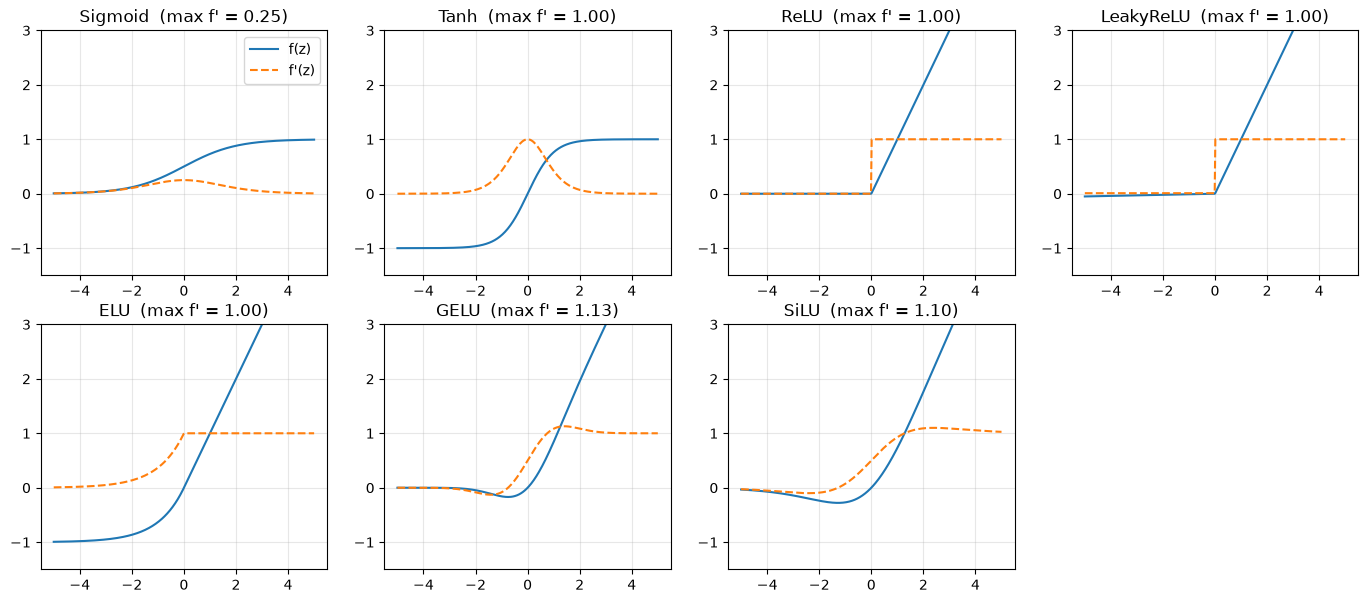

In [2]:
x = torch.linspace(-5, 5, 400, requires_grad=True)
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (name, mk) in zip(axes.ravel(), ACTS.items()):
    y = mk()(x)
    dy, = torch.autograd.grad(y.sum(), x)
    ax.plot(x.detach(), y.detach(), label="f(z)")
    ax.plot(x.detach(), dy, "--", label="f'(z)")
    ax.set(title=f"{name}  (max f' = {dy.max():.2f})", ylim=(-1.5, 3)); ax.grid(alpha=0.3)
axes[0, 0].legend()
axes.ravel()[-1].axis("off")
fig.savefig(REPORTS / "7_activations.png", dpi=150, bbox_inches="tight")

## Bước 6b. Ranh giới quyết định trên make_moons (1.000 điểm) với từng activation

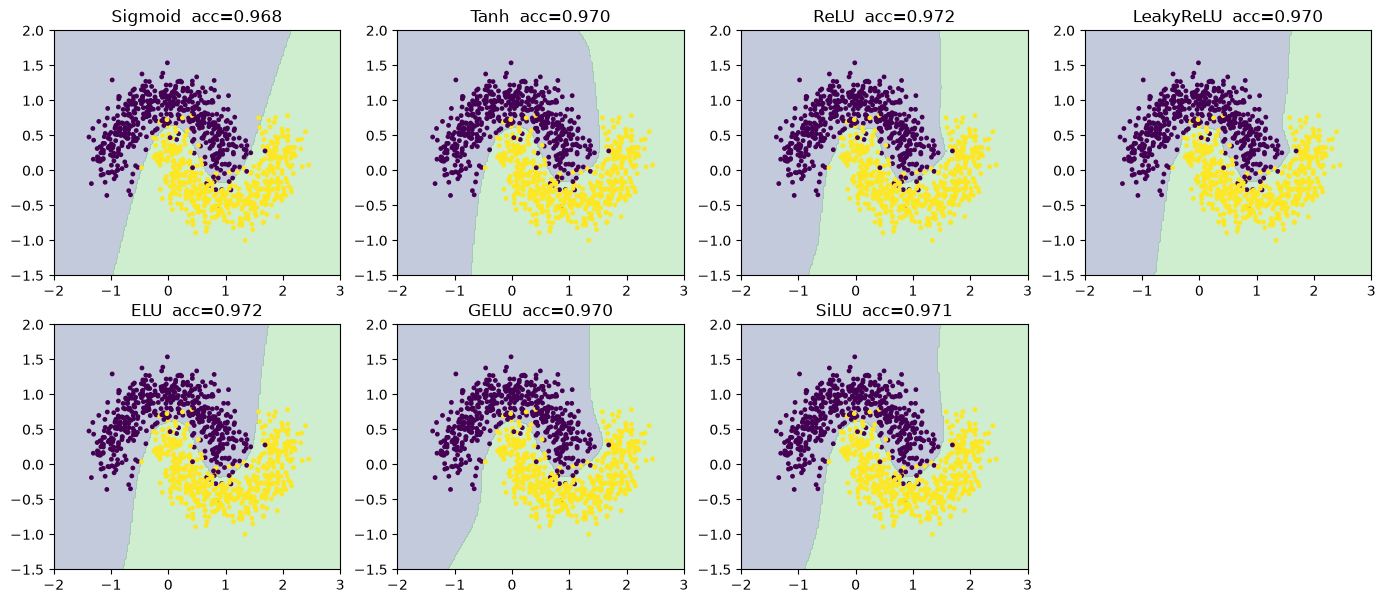

In [3]:
Xm, ym = make_moons(1000, noise=0.2, random_state=0)
Xt, yt = torch.tensor(Xm, dtype=torch.float32), torch.tensor(ym)
gx, gy = torch.meshgrid(torch.linspace(-2, 3, 200), torch.linspace(-1.5, 2, 200), indexing="xy")
grid = torch.stack([gx.ravel(), gy.ravel()], 1)

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (name, mk) in zip(axes.ravel(), ACTS.items()):
    model = make_mlp([2, 32, 32, 2], mk, "he", seed=0)
    opt = torch.optim.Adam(model.parameters(), 1e-2)
    for _ in range(300):
        loss = F.cross_entropy(model(Xt), yt)
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        acc = (model(Xt).argmax(1) == yt).float().mean().item()
        p = model(grid).argmax(1).view(gx.shape)
    ax.contourf(gx, gy, p, levels=[-0.5, 0.5, 1.5], alpha=0.3)
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, s=6); ax.set_title(f"{name}  acc={acc:.3f}")
axes.ravel()[-1].axis("off")
fig.savefig(REPORTS / "moons_boundaries.png", dpi=150, bbox_inches="tight")

## Bước 7. MNIST: giữ nguyên mọi thứ (kiến trúc, init He, lr, momentum, seed, thứ tự batch), chỉ đổi activation

In [4]:
data = load_mnist()
rows = []
for name, mk in ACTS.items():
    model = make_mlp([784, 256, 128, 10], mk, "he", seed=0)
    hist, sec = train(model, data, epochs=10, lr=0.05)
    reach = next((h["epoch"] for h in hist if h["acc"] >= 0.97), np.nan)   # mốc hội tụ: 97% test
    rows.append(dict(activation=name, best_acc=max(h["acc"] for h in hist),
                     epochs_to_97=reach, final_loss=hist[-1]["loss"], seconds=sec))
df_act = pd.DataFrame(rows).round(4)
df_act.to_csv(REPORTS / "activation_mnist.csv", index=False)
df_act

100%|██████████| 9.91M/9.91M [01:03<00:00, 157kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 122kB/s]
100%|██████████| 1.65M/1.65M [00:11<00:00, 148kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.27MB/s]


,activation,best_acc,epochs_to_97,final_loss,seconds
0,Sigmoid,0.9784,5,0.0285,15.1786
1,Tanh,0.9812,3,0.0012,15.4279
2,ReLU,0.9801,2,0.0102,14.6084
3,LeakyReLU,0.9775,3,0.0087,29.6123
4,ELU,0.9829,2,0.0036,46.4528
5,GELU,0.9801,2,0.0078,17.4070
6,SiLU,0.9816,2,0.0044,14.8120


## Bước 8. Mạng 15 tầng: |gradient| theo tầng, sigmoid vs ReLU (mỗi hàm dùng init phù hợp của nó)

Sigmoid: |grad| tầng 1 / tầng 15 = 1.13e-08
ReLU: |grad| tầng 1 / tầng 15 = 1.36e+00


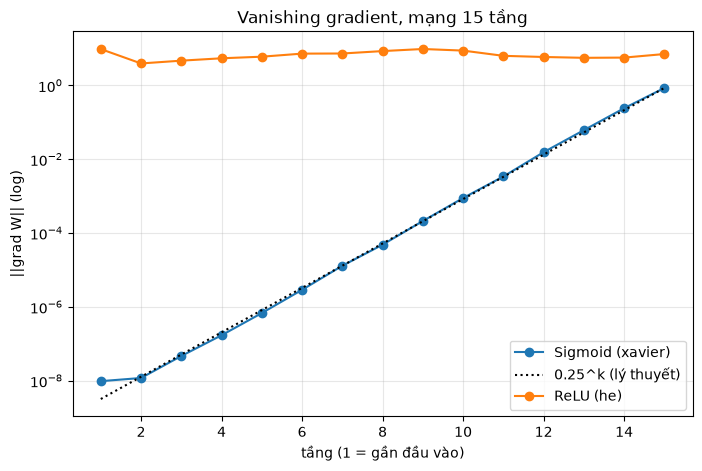

In [5]:
L, ks = 15, np.arange(1, 16)
fig, ax = plt.subplots(figsize=(8, 5))
for name, init in [("Sigmoid", "xavier"), ("ReLU", "he")]:
    g = layer_grad_norms(make_mlp([784] + [100] * (L - 1) + [10], ACTS[name], init), data)
    ax.semilogy(ks, g, "o-", label=f"{name} ({init})")
    print(f"{name}: |grad| tầng 1 / tầng {L} = {g[0] / g[-1]:.2e}")
    if name == "Sigmoid":                              # đường tham chiếu: nhân dồn 0.25 mỗi tầng
        ax.semilogy(ks, g[-1] * 0.25 ** (L - ks), "k:", label="0.25^k (lý thuyết)")
ax.set(xlabel="tầng (1 = gần đầu vào)", ylabel="||grad W|| (log)", title="Vanishing gradient, mạng 15 tầng")
ax.legend(); ax.grid(alpha=0.3)
fig.savefig(REPORTS / "vanishing_gradient.png", dpi=150, bbox_inches="tight")

## Bước 9. Dying ReLU: lr lớn, SGD thuần. Neuron chết = z <= 0 với mọi mẫu train

In [6]:
rows = []
for name in ["ReLU", "LeakyReLU"]:
    for lr in [0.01, 0.1, 0.5, 1, 2, 5]:
        model = make_mlp([784, 256, 256, 256, 10], ACTS[name], "he", seed=0)
        hist, _ = train(model, data, epochs=3, lr=lr, momentum=0.0)
        ok = all(torch.isfinite(p).all() for p in model.parameters())
        rows.append(dict(activation=name, lr=lr, test_acc=hist[-1]["acc"], diverged=not ok,
                         dead_pct=100 * dead_fraction(model, data[0]) if ok else np.nan))
df_dead = pd.DataFrame(rows).round(4)
df_dead.to_csv(REPORTS / "dying_relu.csv", index=False)
df_dead.pivot(index="lr", columns="activation", values="dead_pct")

activation,LeakyReLU,ReLU
lr,,
0.01,0.1302,0.1302
0.10,0.0000,0.0000
0.50,NaN,NaN
1.00,NaN,NaN
2.00,NaN,NaN
5.00,NaN,NaN
